# Hands-on 2, Chapter 1: Thinking in Jasp

Jasp traces a Qrisp function into a compact program (a *Jaspr*) with rolled loops and real-time classical logic.
In this chapter you practise the habits that make Jasp programs work: telling static from dynamic values,
branching on measurements, keeping loops rolled, and running the same code as a simulator, a resource counter or a classical verifier.

* **core**: fits the session (about 40 minutes); **stretch**: for fast participants.
* Every exercise ends with a check cell that prints ✅ or ❌ with a hint.
* Stuck? The solutions are in `ch1_jasp_solutions.ipynb`.
* Background reading: the Jasp tutorial at [qrisp.eu](https://qrisp.eu/general/tutorial/Jasp.html).

In [1]:
# %pip install qrisp matplotlib  # uncomment on Colab

import time
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import networkx as nx

from qrisp import *
from qrisp.jasp import jrange, RUS, make_jaspr, qache, boolean_simulation
from qrisp.operators import X, Y, Z


def check(test, hint, success="Correct!"):
    """Run test() and print ✅ on success or ❌ with a hint."""
    try:
        ok = bool(test())
    except NotImplementedError:
        ok, hint = False, "not implemented yet. " + hint
    except Exception as e:
        ok, hint = False, f"{type(e).__name__}: {e}. " + hint
    print(f"✅ {success}" if ok else f"❌ Not yet: {hint}")

### Jasp gotchas

| Situation | What happens in Jasp |
|---|---|
| `for i in range(n)` | Python unrolls the loop while tracing; `n` must be a static value. Use `jrange(n)` to keep the loop rolled. |
| `if measure(qb):` | Fails while tracing: the outcome does not exist yet. Use `with control(measure(qb)):`. An `if` on a *static* value is fine and decides which program is built. |
| `print(x)` inside a traced function | Shows a tracer such as `Traced<int64[]>`, not a value. |
| `@terminal_sampling` | Simulates once and samples the final measurement. Use `@jaspify` (one shot per call) when the result depends on mid-circuit measurements, as in teleportation. |
| `@count_ops`, `@boolean_simulation` | The first call compiles the program; later calls are much faster. |

## Exercise 1.1: Static or dynamic? (core, 5 min)

When Jasp traces a function, every value is either **static** (known while tracing: Python numbers, NumPy arrays)
or **dynamic** (known only when the program runs). Dynamic values are JAX *tracers*.

The function `probe` below records eight expressions. **Predict first:** which of them are tracers?
Fill in `True` (tracer, dynamic) or `False` (static) for each key.

In [2]:
record = {}

def probe(n):
    qv = QuantumFloat(n)
    h(qv)
    k = 3
    m = measure(qv)
    arr = np.arange(4)
    record.update({
        "n": n,                    # the function argument
        "qv.size": qv.size,
        "k": k,
        "m": m,                    # a measurement result
        "arr": arr,
        "m + k": m + k,
        "len(arr)": len(arr),
        "jnp.sin(k)": jnp.sin(k),
    })
    for i in jrange(2):
        record["i"] = i            # the index of a jrange loop
    return m

In [3]:
# True = tracer (dynamic), False = static
predictions = {
    "n": True,           # arguments of the traced function are dynamic
    "qv.size": True,     # derived from n
    "k": False,          # a plain Python int
    "m": True,           # measurement results exist only at runtime
    "arr": False,        # a NumPy array is a constant
    "m + k": True,       # dynamic + static = dynamic
    "len(arr)": False,   # Python computes it while tracing
    "jnp.sin(k)": True,  # jax.numpy calls inside a trace are recorded
    "i": True,           # the jrange index is a loop variable of the program
}

In [4]:
make_jaspr(probe)(5)
actual = {key: isinstance(value, jax.core.Tracer) for key, value in record.items()}

def test_predictions():
    wrong = [key for key in actual if predictions.get(key) is not actual[key]]
    if wrong:
        print("Re-think:", ", ".join(wrong))
    return not wrong

check(test_predictions, "a value is dynamic if it depends on an argument, a measurement or a jax.numpy call.")

✅ Correct!


Surprised by `jnp.sin(k)`? Inside a trace, `jax.numpy` calls are recorded into the program even for static inputs.
Use `np.sin` if you want the value computed while tracing.

## Exercise 1.2: Fix the `if` (core, 10 min)

Quantum teleportation needs two corrections that depend on mid-circuit measurements.
The version below uses `if` on a measurement result and fails while tracing. Run it to see the error.

In [5]:
def teleport_with_if(theta):
    psi, a, b = QuantumBool(), QuantumBool(), QuantumBool()
    ry(theta, psi)            # the state to teleport
    h(a); cx(a, b)            # Bell pair
    cx(psi, a); h(psi)        # Bell measurement basis
    if measure(a):
        x(b)
    if measure(psi):
        z(b)
    return measure(b)

try:
    jaspify(teleport_with_if)(np.pi)
except Exception as e:
    print(type(e).__name__)

TracerBoolConversionError


Now write `teleport` with `control` so that the corrections are decided **at runtime**.
`ry(theta)` prepares $\cos(\theta/2)\lvert 0\rangle + \sin(\theta/2)\lvert 1\rangle$, so `b` must read 1 with probability $\sin^2(\theta/2)$.

In [6]:
@jaspify
def teleport(theta):
    psi, a, b = QuantumBool(), QuantumBool(), QuantumBool()
    ry(theta, psi)
    h(a); cx(a, b)
    cx(psi, a); h(psi)
    with control(measure(a)):
        x(b)
    with control(measure(psi)):
        z(b)
    return measure(b)

In [7]:
def test_teleport():
    ones = [bool(teleport(np.pi)) for _ in range(20)]
    zeros = [bool(teleport(0.0)) for _ in range(20)]
    p1 = np.mean([bool(teleport(2 * np.pi / 3)) for _ in range(100)])
    print(f"theta = pi: {sum(ones)}/20 ones, theta = 0: {sum(zeros)}/20 ones, "
          f"theta = 2pi/3: P(1) = {p1:.2f} (expected 0.75)")
    return all(ones) and not any(zeros) and abs(p1 - 0.75) < 0.15

check(test_teleport, "apply x(b) controlled on measure(a) and z(b) controlled on measure(psi).")

theta = pi: 20/20 ones, theta = 0: 0/20 ones, theta = 2pi/3: P(1) = 0.70 (expected 0.75)
✅ Correct!


## Exercise 1.3: Scale it (core, 10 min)

`ghz_range` prepares a GHZ state with a Python `range` loop. While tracing, Python unrolls this loop,
so the Jaspr grows with `n` (and `n` must be static). Write `ghz_jrange`, the same function with `jrange`.

**Predict first:** how does the tracing time of each version grow from `n = 10` to `n = 1000`?
`range`: roughly linearly with `n`, one recorded `cx` per iteration. `jrange`: constant, the loop body is traced once.

In [8]:
def ghz_range(n):
    qv = QuantumVariable(n)
    h(qv[0])
    for i in range(n - 1):
        cx(qv[0], qv[i + 1])
    return measure(qv)


def ghz_jrange(n):
    qv = QuantumVariable(n)
    h(qv[0])
    for i in jrange(n - 1):
        cx(qv[0], qv[i + 1])
    return measure(qv)

n =    10: range     3.5 ms, jrange     6.5 ms
n =   100: range    21.1 ms, jrange     6.0 ms
n =  1000: range   451.0 ms, jrange     6.1 ms


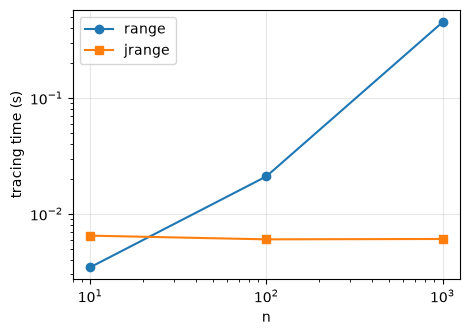

In [9]:
def trace_time(f, n):
    t0 = time.time()
    make_jaspr(lambda: f(n))()   # n is a static value in this closure
    return time.time() - t0

sizes = [10, 100, 1000]
times_range = [trace_time(ghz_range, n) for n in sizes]
times_jrange = [trace_time(ghz_jrange, n) for n in sizes]
for n, tr, tj in zip(sizes, times_range, times_jrange):
    print(f"n = {n:5d}: range {tr*1000:7.1f} ms, jrange {tj*1000:7.1f} ms")

plt.figure(figsize=(5, 3.5))
plt.loglog(sizes, times_range, "o-", label="range")
plt.loglog(sizes, times_jrange, "s-", label="jrange")
plt.xlabel("n"); plt.ylabel("tracing time (s)"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

With a rolled loop, `n` can also be a **dynamic** argument. Count the gates of a one-million-qubit GHZ state:

In [10]:
def test_scale():
    counts = count_ops(meas_behavior="0")(ghz_jrange)(10**6)
    print(counts)
    fast = times_jrange[-1] < times_range[-1] / 5
    return counts == {"h": 1, "cx": 10**6 - 1, "measure": 10**6} and fast

check(test_scale, "use jrange(n - 1) so that the loop stays rolled and n may be dynamic.")

{'h': 1, 'cx': 999999, 'measure': 1000000}
✅ Correct!


## Exercise 1.4: Repeat until success (core, 15 min)

Goal: a uniform superposition over $\{0, 1, \dots, k-1\}$ for a $k$ that is not a power of two, here $k = 5$.

Recipe for one trial: Hadamards on a 3-qubit `QuantumFloat` give $0, \dots, 7$; the comparison `qf < k` computes a `QuantumBool`;
measuring it tells you whether the trial succeeded. The `@RUS` decorator repeats the trial until the first return value is `True`.
After measuring the comparison bool, `reset` and `delete` it.

**Predict first:** what is the success probability of one trial, and how many trials are needed on average?
$5/8$ per trial, so on average $8/5 = 1.6$ trials.

In [11]:
@RUS
def uniform_trial(k):
    qf = QuantumFloat(3)
    h(qf)
    qbl = qf < k
    success = measure(qbl)
    reset(qbl)
    qbl.delete()
    return success, qf


@terminal_sampling
def uniform(k):
    return uniform_trial(k)

In [12]:
def test_rus():
    dist = uniform(5)
    print("distribution:", dist)
    return set(dist) == set(range(5)) and all(abs(p - 0.2) < 1e-6 for p in dist.values())

check(test_rus, "return (success, qf) from the trial, where success = measure(qf < k).")

distribution: {0.0: 0.2, 1.0: 0.2, 2.0: 0.2, 3.0: 0.2, 4.0: 0.2}
✅ Correct!


## Exercise 1.5: Measurement-based uncomputation (stretch)

A logical AND computed into a fresh qubit `xy` (with `mcx(..., method="gidney")`) can be uncomputed without any T gate (Gidney 2018):
measure `xy` in the X basis (`h`, then `measure`); if the outcome is 1, apply `cz(x, y)`; finally `reset(xy)`.
Implement `uncompute_and` and compare the T count with a plain `mcx` uncomputation.

In [13]:
def uncompute_and(x_, y_, xy):
    h(xy)
    b = measure(xy)
    with control(b):
        cz(x_, y_)
    reset(xy)

In [14]:
@jaspify
def and_roundtrip(i, j):
    x_, y_, xy = QuantumBool(), QuantumBool(), QuantumBool()
    with control(i):
        x(x_)
    with control(j):
        x(y_)
    mcx([x_, y_], xy, method="gidney")
    uncompute_and(x_, y_, xy)
    return measure(x_), measure(y_), measure(xy)


def t_count(uncompute):
    @count_ops(meas_behavior="1")
    def program():
        x_, y_, xy = QuantumBool(), QuantumBool(), QuantumBool()
        mcx([x_, y_], xy, method="gidney")
        uncompute(x_, y_, xy)
        return measure(x_)
    counts = program()
    return counts.get("t", 0) + counts.get("t_dg", 0)


def test_mbu():
    correct = all(
        tuple(bool(v) for v in and_roundtrip(i, j)) == (bool(i), bool(j), False)
        for i in (0, 1) for j in (0, 1) for _ in range(3)
    )
    t_mbu = t_count(uncompute_and)
    t_plain = t_count(lambda x_, y_, xy: mcx([x_, y_], xy))
    print(f"T gates: measurement-based {t_mbu}, plain mcx {t_plain} (compute + uncompute)")
    return correct and t_mbu < t_plain

check(test_mbu, "h, measure, a controlled cz, then reset: no T gates in the uncomputation.")

T gates: measurement-based 4, plain mcx 11 (compute + uncompute)
✅ Correct!


## Exercise 1.6: Bug hunt with boolean simulation (stretch)

`buggy_oracle` flips `res` by the parity of `a AND b` for two 500-bit registers, using `anc` as scratch space.
It is supposed to return `anc` to zero, but it contains an uncomputation bug.
With 1501 qubits this is far beyond state-vector simulation, but the oracle only uses X, CX and Toffoli gates,
so `@boolean_simulation` runs it as a classical bit-array program.

1. Complete `ancilla_test`: run the oracle and return whether `anc` is clean, plus `res` and the expected parity.
2. Find random keys for which the buggy oracle leaves `anc` dirty.
3. Write `fixed_oracle`.

**Predict first:** does the bug make `res` wrong?
No. `res` is computed before the faulty uncomputation, so it is always correct. The bug only shows up as a dirty ancilla,
which would silently break interference in a larger algorithm (for example inside Grover's diffuser).

In [15]:
N_BITS = 500


def buggy_oracle(a, b, anc, res):
    for i in jrange(a.size):
        mcx([a[i], b[i]], anc[i])      # anc[i] = a[i] AND b[i]
    for i in jrange(anc.size):
        cx(anc[i], res[0])             # res ^= parity(anc)
    for i in jrange(a.size - 1):
        mcx([a[i], b[i]], anc[i])      # uncompute anc


def prepare(qv, bits):
    """Encode a classical bit array into a QuantumVariable."""
    for i in jrange(qv.size):
        with control(bits[i]):
            x(qv[i])


def is_zero(qv, chunk=50):
    """True if every qubit of qv (N_BITS qubits) measures 0.
    Chunks keep the measured integers within 64 bits. The loop bound uses the
    static N_BITS: inside the trace, qv.size is a tracer (Exercise 1.1)."""
    clean = True
    for j in range(N_BITS // chunk):
        clean = clean & (measure(qv[chunk * j: chunk * (j + 1)]) == 0)
    return clean

In [16]:
def make_ancilla_test(oracle):
    @boolean_simulation
    def ancilla_test(key):
        key_a, key_b = jax.random.split(key)
        bits_a = jax.random.bernoulli(key_a, shape=(N_BITS,))
        bits_b = jax.random.bernoulli(key_b, shape=(N_BITS,))
        a, b, anc = QuantumVariable(N_BITS), QuantumVariable(N_BITS), QuantumVariable(N_BITS)
        res = QuantumBool()
        prepare(a, bits_a)
        prepare(b, bits_b)
        expected = jnp.sum(bits_a & bits_b) % 2 == 1
        oracle(a, b, anc, res)
        return is_zero(anc), measure(res), expected
    return ancilla_test

In [17]:
def fixed_oracle(a, b, anc, res):
    for i in jrange(a.size):
        mcx([a[i], b[i]], anc[i])
    for i in jrange(anc.size):
        cx(anc[i], res[0])
    for i in jrange(a.size):           # uncompute every bit, including the last one
        mcx([a[i], b[i]], anc[i])

In [18]:
def run_keys(oracle, n_keys=40):
    test = make_ancilla_test(oracle)
    results = [test(jax.random.key(s)) for s in range(n_keys)]
    dirty = [s for s, r in enumerate(results) if not bool(r[0])]
    res_ok = all(bool(r[1]) == bool(r[2]) for r in results)
    return dirty, res_ok


def test_bug_hunt():
    dirty_buggy, res_ok_buggy = run_keys(buggy_oracle)
    dirty_fixed, res_ok_fixed = run_keys(fixed_oracle)
    print(f"buggy oracle: dirty ancillas for keys {dirty_buggy[:8]}..., res correct: {res_ok_buggy}")
    print(f"fixed oracle: dirty ancillas for keys {dirty_fixed}, res correct: {res_ok_fixed}")
    return len(dirty_buggy) > 0 and not dirty_fixed and res_ok_fixed

check(test_bug_hunt, "compare the compute loop and the uncompute loop of buggy_oracle bit by bit.")

buggy oracle: dirty ancillas for keys [2, 3, 5, 16, 26, 30, 34, 35]..., res correct: True
fixed oracle: dirty ancillas for keys [], res correct: True
✅ Correct!


## Exercise 1.7: Back to Lecture 1 (stretch)

Quantum phase estimation on a Trotterized Heisenberg chain: how do the gate counts grow with the number of sites `n`?
Write `qpe_cost(n)`: build the Hamiltonian, Trotterize it (wrap the result in `qache` so it is traced only once),
run `QPE(psi, U, precision=4)` on a fresh `QuantumVariable(n)` inside a `@count_ops(meas_behavior="0")` function, and return the counts.

In [19]:
def heisenberg(n):
    G = nx.path_graph(n)
    return sum(X(i)*X(j) + Y(i)*Y(j) + Z(i)*Z(j) for i, j in G.edges())


def qpe_cost(n, precision=4):
    U = qache(heisenberg(n).trotterization())

    @count_ops(meas_behavior="0")
    def program():
        psi = QuantumVariable(n)
        res = QPE(psi, U, precision=precision)
        return measure(res)

    return program()

n =   4:    270 rz,    558 cx
n =   8:    630 rz,   1278 cx
n =  16:   1350 rz,   2718 cx
n =  32:   2790 rz,   5598 cx
n =  64:   5670 rz,  11358 cx


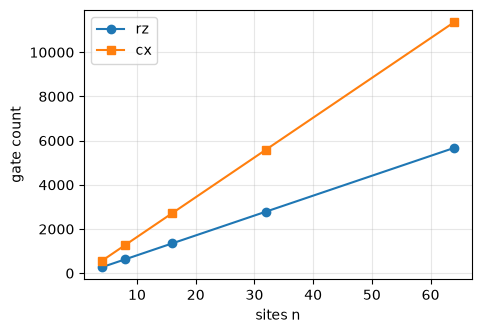

✅ Correct!


In [20]:
def test_qpe_scaling():
    sites = [4, 8, 16, 32, 64]
    costs = [qpe_cost(n) for n in sites]
    rz = [c["rz"] for c in costs]
    cx_ = [c["cx"] for c in costs]
    for n, r, c in zip(sites, rz, cx_):
        print(f"n = {n:3d}: {r:6d} rz, {c:6d} cx")
    plt.figure(figsize=(5, 3.5))
    plt.plot(sites, rz, "o-", label="rz")
    plt.plot(sites, cx_, "s-", label="cx")
    plt.xlabel("sites n"); plt.ylabel("gate count"); plt.legend(); plt.grid(alpha=0.3)
    plt.show()
    # n - 1 edges, each contributing the same number of gates: linear growth
    return (rz[2] - rz[1]) == 2 * (rz[1] - rz[0]) and rz[-1] > rz[0]

check(test_qpe_scaling, "return the dictionary produced by the count_ops-decorated function.")

---
**Next:** Chapter 2 (`ch2_repetition_code_exercises.ipynb`) turns these tools into a quantum error-correction experiment.